# 4. Trực quan hóa Kết quả Mô hình & Giải thích Mô hình (XAI — Grad-CAM & Saliency)

Notebook này tổng hợp toàn bộ bảng biểu, ma trận và hình trực quan hóa phục vụ báo cáo và slide thuyết trình:
1. **Thiết lập môi trường, nạp tập Validation/Test & Best Checkpoint (`inception_bigru_best.pt`)**
2. **Bảng Classification Report đầy đủ (`support`, `micro/macro/weighted/samples avg`) — Trước và Sau khi Threshold Tuning**
3. **Đường cong ROC (ROC Curves) & Precision-Recall (PR Curves) trên tập Test**
4. **Bộ 5 Ma trận nhầm lẫn đa nhãn (`Multilabel Confusion Matrices` $2 \times 2$) — Trước (`0.5`) vs. Sau khi tối ưu ngưỡng (`CD = 0.5`)**
5. **Ma trận Đồng xuất hiện 5 nhóm bệnh lý (`Co-occurrence Heatmap` $5 \times 5$)**
6. **1D Grad-CAM cho 10 ca `NORM` điển hình (Độ tự tin cao)**
7. **1D Grad-CAM cho các ca Bệnh lý (`MI`, `STTC`, `CD`, `HYP`, Đa nhãn) & Phân tích Ca hạn chế/Nhiễu**
8. **Ma trận Đóng góp của 12 Chuyển đạo theo 5 Nhóm bệnh ($12 \times 5$ Heatmap) & Đóng góp Đa phương thức (`ECG` vs. `Clinical`)**

## 1. Thiết lập môi trường, Nạp dữ liệu & Best Checkpoint

In [1]:
from pathlib import Path
import ast
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import (
    auc,
    average_precision_score,
    classification_report,
    multilabel_confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from torch.utils.data import DataLoader

plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 220

current_dir = Path.cwd().resolve()
project_root = next(
    (path for path in (current_dir, *current_dir.parents)
     if (path / 'data' / 'processed' / 'ptbxl_recordwise_leadwise_zscore_500hz.npy').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Không tìm thấy thư mục gốc dự án.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data import PTBXLMultiModalDataset, SUPERCLASSES, assert_patient_disjoint
from src.engine import evaluate_predictions, find_optimal_thresholds, run_epoch
from src.models import InceptionBiGRUClassifier

data_dir = project_root / 'data'
processed_dir = data_dir / 'processed'
figures_dir = project_root / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)

signal_path = processed_dir / 'ptbxl_recordwise_leadwise_zscore_500hz.npy'
signal_index_path = processed_dir / 'ptbxl_recordwise_leadwise_zscore_500hz_index.csv'
clinical_path = processed_dir / 'ptbxl_clinical_features_age_zscore_sex_binary.csv'
checkpoint_path = project_root / 'models' / 'checkpoints' / 'inception_bigru_best.pt'

metadata = pd.read_csv(data_dir / 'ptbxl_database.csv', encoding='latin-1')
scp_statements = pd.read_csv(data_dir / 'scp_statements.csv', index_col=0)
signal_index = pd.read_csv(signal_index_path)
clinical_features = pd.read_csv(clinical_path)

diagnostic = scp_statements.loc[scp_statements['diagnostic'].eq(1.0)]
superclass_lookup = {
    str(code): str(row['diagnostic_class'])
    for code, row in diagnostic.iterrows()
    if pd.notna(row.get('diagnostic_class')) and str(row['diagnostic_class']) in SUPERCLASSES
}
form_rhythm_codes = {
    str(code) for code, row in scp_statements.iterrows()
    if row.get('form') == 1.0 or row.get('rhythm') == 1.0
}

def parse_scp_codes(value):
    if pd.isna(value):
        return {}
    try:
        parsed = ast.literal_eval(value)
    except (TypeError, ValueError, SyntaxError):
        return {}
    return parsed if isinstance(parsed, dict) else {}

def is_form_rhythm_only_unmapped(value):
    codes = set(parse_scp_codes(value))
    return bool(codes) and codes.issubset(form_rhythm_codes) and codes.isdisjoint(superclass_lookup)

review_patient_ids = set(
    metadata.loc[metadata['scp_codes'].map(is_form_rhythm_only_unmapped), 'patient_id']
)
records = signal_index.merge(clinical_features, on='ecg_id', how='inner', validate='one_to_one')
eligible = records.loc[~records['patient_id'].isin(review_patient_ids)].copy()

val_records = eligible.loc[eligible['strat_fold'].eq(9)].copy()
test_records = eligible.loc[eligible['strat_fold'].eq(10)].copy()
assert_patient_disjoint(val_records, test_records)

val_dataset = PTBXLMultiModalDataset(val_records, signal_path, signal_index_path, clinical_path, expected_folds={9})
test_dataset = PTBXLMultiModalDataset(test_records, signal_path, signal_index_path, clinical_path, expected_folds={10})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

model = InceptionBiGRUClassifier().to(device)
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

val_outputs = run_epoch(model, val_loader, device, amp=True, detailed_metrics=True, threshold=0.5, return_predictions=True)
test_outputs = run_epoch(model, test_loader, device, amp=True, detailed_metrics=True, threshold=0.5, return_predictions=True)

tuned_thresholds = find_optimal_thresholds(val_outputs['targets'], val_outputs['probabilities'], betas=1.0)
tuned_thresholds['CD'] = 0.5

print(f'Loaded checkpoint from Epoch {checkpoint["epoch"]} on {device}')
print('Validation records:', len(val_dataset), '| Test records:', len(test_dataset))
print('Tuned thresholds (Scenario B, CD=0.5):', tuned_thresholds)

Loaded checkpoint from Epoch 12 on cuda
Validation records: 2150 | Test records: 2150
Tuned thresholds (Scenario B, CD=0.5): {'NORM': 0.645, 'MI': 0.145, 'STTC': 0.495, 'CD': 0.5, 'HYP': 0.27}


## 2. Bảng Classification Report đầy đủ trên tập Test (Trước & Sau khi Threshold Tuning)

Xuất đầy đủ các chỉ số `precision`, `recall`, `f1-score`, `support`, `micro avg`, `macro avg`, `weighted avg`, `samples avg` và `AUROC` / `AUPRC` giống định dạng chuẩn để đưa lên Slide.

In [2]:
y_true_test = test_outputs['targets'].astype(int)
y_prob_test = test_outputs['probabilities']

y_pred_default = (y_prob_test >= 0.5).astype(int)
thresh_vec = np.array([tuned_thresholds[label] for label in SUPERCLASSES], dtype=np.float32)
y_pred_tuned = (y_prob_test >= thresh_vec[np.newaxis, :]).astype(int)

print('=' * 72)
print('KẾT QUẢ TẬP TEST — TRƯỚC KHI TỐI ƯU NGƯỠNG (THRESHOLD CỐ ĐỊNH = 0.5)')
print('=' * 72)
print(classification_report(y_true_test, y_pred_default, target_names=list(SUPERCLASSES), digits=4, zero_division=0))

print('=' * 72)
print('KẾT QUẢ TẬP TEST — SAU KHI TỐI ƯU NGƯỠNG (KỊCH BẢN B, RIÊNG CD = 0.5)')
print('Ngưỡng áp dụng:', tuned_thresholds)
print('=' * 72)
print(classification_report(y_true_test, y_pred_tuned, target_names=list(SUPERCLASSES), digits=4, zero_division=0))

print('-' * 72)
print('CHỈ SỐ ĐỘC LẬP NGƯỠNG (AUROC & AUPRC) TRÊN TẬP TEST:')
for idx, label in enumerate(SUPERCLASSES):
    auroc = roc_auc_score(y_true_test[:, idx], y_prob_test[:, idx])
    auprc = average_precision_score(y_true_test[:, idx], y_prob_test[:, idx])
    print(f'  {label:<5} | AUROC: {auroc:.4f} | AUPRC: {auprc:.4f} | Support: {int(y_true_test[:, idx].sum())}')
print('=' * 72)

KẾT QUẢ TẬP TEST — TRƯỚC KHI TỐI ƯU NGƯỠNG (THRESHOLD CỐ ĐỊNH = 0.5)
              precision    recall  f1-score   support

        NORM     0.7878    0.9291    0.8526       959
          MI     0.8450    0.5064    0.6333       549
        STTC     0.7278    0.7712    0.7488       520
          CD     0.7454    0.7348    0.7401       494
         HYP     0.5942    0.3118    0.4090       263

   micro avg     0.7644    0.7235    0.7434      2785
   macro avg     0.7400    0.6506    0.6768      2785
weighted avg     0.7621    0.7235    0.7281      2785
 samples avg     0.7600    0.7484    0.7376      2785

KẾT QUẢ TẬP TEST — SAU KHI TỐI ƯU NGƯỠNG (KỊCH BẢN B, RIÊNG CD = 0.5)
Ngưỡng áp dụng: {'NORM': 0.645, 'MI': 0.145, 'STTC': 0.495, 'CD': 0.5, 'HYP': 0.27}
              precision    recall  f1-score   support

        NORM     0.8101    0.8853    0.8460       959
          MI     0.6852    0.7614    0.7213       549
        STTC     0.7261    0.7750    0.7498       520
          CD     

## 3. Đường cong ROC (ROC Curves) & Đường cong Precision-Recall (PR Curves) trên tập Test

Vẽ đường cong ROC và PR cho cả 5 nhóm chẩn đoán, đồng thời đánh dấu điểm hoạt động ứng với bộ ngưỡng tối ưu $\tau_c^*$.

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\test_roc_pr_curves.png


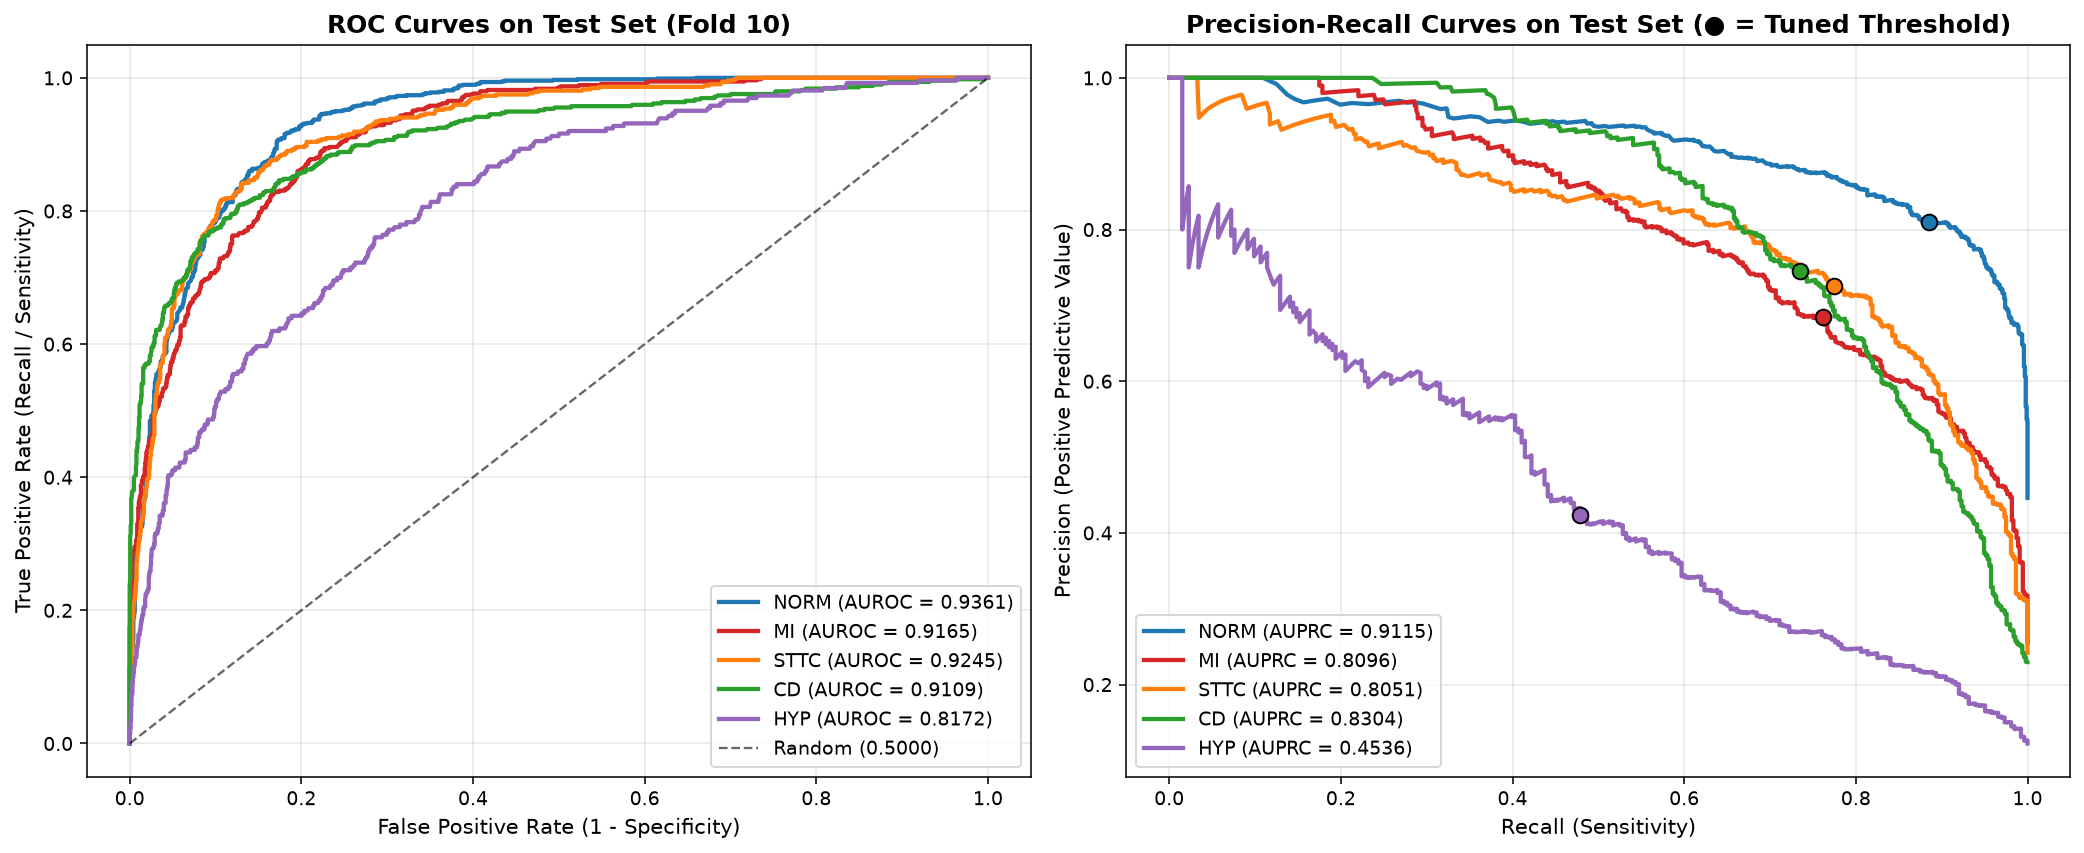

In [3]:
colors = {'NORM': '#1f77b4', 'MI': '#d62728', 'STTC': '#ff7f0e', 'CD': '#2ca02c', 'HYP': '#9467bd'}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))

# 1. ROC Curves
ax_roc = axes[0]
for idx, label in enumerate(SUPERCLASSES):
    fpr, tpr, _ = roc_curve(y_true_test[:, idx], y_prob_test[:, idx])
    roc_auc = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, color=colors[label], lw=2.2, label=f'{label} (AUROC = {roc_auc:.4f})')

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1.2, alpha=0.6, label='Random (0.5000)')
ax_roc.set_title('ROC Curves on Test Set (Fold 10)', fontsize=13, fontweight='bold')
ax_roc.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax_roc.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
ax_roc.legend(loc='lower right', frameon=True, fontsize=10)
ax_roc.grid(True, alpha=0.3)

# 2. Precision-Recall Curves
ax_pr = axes[1]
for idx, label in enumerate(SUPERCLASSES):
    precision_c, recall_c, _ = precision_recall_curve(y_true_test[:, idx], y_prob_test[:, idx])
    ap = average_precision_score(y_true_test[:, idx], y_prob_test[:, idx])
    ax_pr.plot(recall_c, precision_c, color=colors[label], lw=2.2, label=f'{label} (AUPRC = {ap:.4f})')
    # Đánh dấu điểm ngưỡng tối ưu
    pred_c = y_pred_tuned[:, idx]
    tp = np.sum((pred_c == 1) & (y_true_test[:, idx] == 1))
    fp = np.sum((pred_c == 1) & (y_true_test[:, idx] == 0))
    fn = np.sum((pred_c == 0) & (y_true_test[:, idx] == 1))
    pt_rec = tp / max(tp + fn, 1)
    pt_prec = tp / max(tp + fp, 1)
    ax_pr.scatter([pt_rec], [pt_prec], color=colors[label], edgecolors='black', s=65, zorder=5)

ax_pr.set_title('Precision-Recall Curves on Test Set (● = Tuned Threshold)', fontsize=13, fontweight='bold')
ax_pr.set_xlabel('Recall (Sensitivity)', fontsize=11)
ax_pr.set_ylabel('Precision (Positive Predictive Value)', fontsize=11)
ax_pr.legend(loc='lower left', frameon=True, fontsize=10)
ax_pr.grid(True, alpha=0.3)

plt.tight_layout()
roc_pr_path = figures_dir / 'test_roc_pr_curves.png'
fig.savefig(roc_pr_path, bbox_inches='tight')
plt.show()
print('Saved figure:', roc_pr_path)

## 4. Bộ 5 Ma trận nhầm lẫn đa nhãn (`Multilabel Confusion Matrices` $2 \times 2$)

So sánh trực tiếp 5 ma trận nhầm lẫn của 5 nhóm bệnh trên tập Test:
- **Hàng trên:** Ngưỡng cố định $\tau = 0.5$.
- **Hàng dưới:** Sau khi tối ưu ngưỡng (Kịch bản B, giữ `CD = 0.5`) — cho thấy số ca bỏ sót bệnh (**FN**, ô dưới bên trái) giảm mạnh ở `MI` (từ `260` $\rightarrow$ `126`) và `HYP` (từ `181` $\rightarrow$ `137`).

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\test_multilabel_confusion_matrices.png


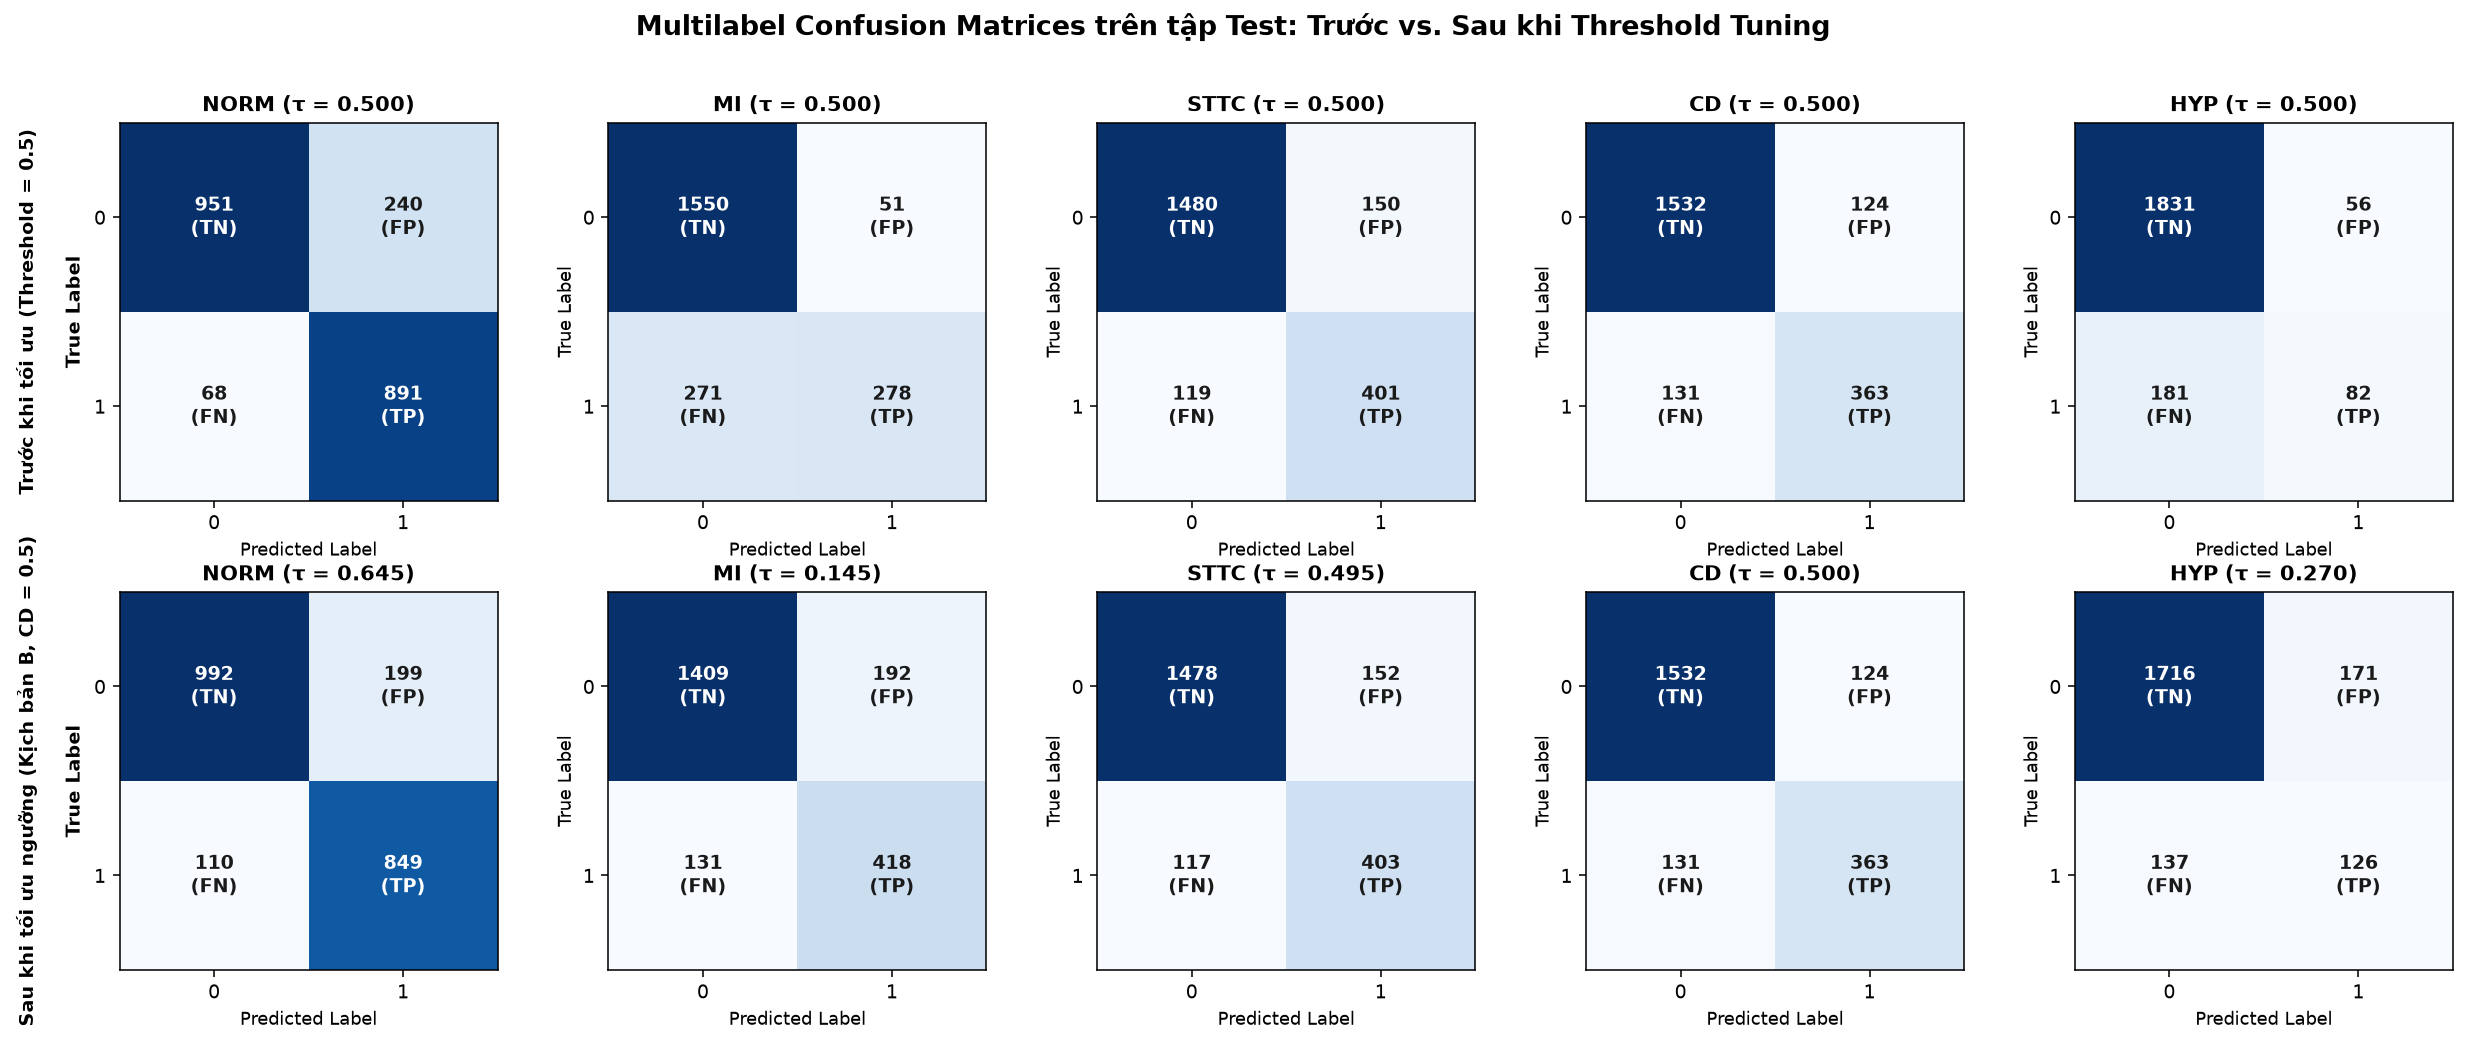

In [4]:
mcm_default = multilabel_confusion_matrix(y_true_test, y_pred_default)
mcm_tuned = multilabel_confusion_matrix(y_true_test, y_pred_tuned)

fig, axes = plt.subplots(2, 5, figsize=(18, 7.2))

for row_idx, (mcm, row_title, thresh_info) in enumerate([
    (mcm_default, 'Trước khi tối ưu (Threshold = 0.5)', {label: 0.5 for label in SUPERCLASSES}),
    (mcm_tuned, 'Sau khi tối ưu ngưỡng (Kịch bản B, CD = 0.5)', tuned_thresholds),
]):
    for col_idx, label in enumerate(SUPERCLASSES):
        ax = axes[row_idx, col_idx]
        cm = mcm[col_idx]
        im = ax.imshow(cm, cmap='Blues', interpolation='nearest')
        ax.set_title(f'{label} (τ = {thresh_info[label]:.3f})', fontsize=11, fontweight='bold')
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(['0', '1'])
        ax.set_yticklabels(['0', '1'])
        if col_idx == 0:
            ax.set_ylabel(f'{row_title}\n\nTrue Label', fontsize=10, fontweight='bold')
        else:
            ax.set_ylabel('True Label', fontsize=9)
        ax.set_xlabel('Predicted Label', fontsize=9)

        thresh_color = cm.max() / 2.0
        tag_names = [['TN', 'FP'], ['FN', 'TP']]
        for i in range(2):
            for j in range(2):
                val = int(cm[i, j])
                ax.text(
                    j, i, f'{val}\n({tag_names[i][j]})',
                    ha='center', va='center', fontsize=10, fontweight='bold',
                    color='white' if val > thresh_color else '#1a1a1a',
                )

fig.suptitle('Multilabel Confusion Matrices trên tập Test: Trước vs. Sau khi Threshold Tuning', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
cm_path = figures_dir / 'test_multilabel_confusion_matrices.png'
fig.savefig(cm_path, bbox_inches='tight')
plt.show()
print('Saved figure:', cm_path)

## 5. Ma trận Đồng xuất hiện 5 nhóm bệnh lý (`Disease Co-occurrence Heatmap` $5 \times 5$)

Trực quan hóa sự chồng lấp đa nhãn giữa 5 superclass trên toàn bộ dữ liệu để minh họa bản chất Multi-label (tương tự Slide 9 của nhóm kỳ trước).

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\superclass_cooccurrence_heatmap.png


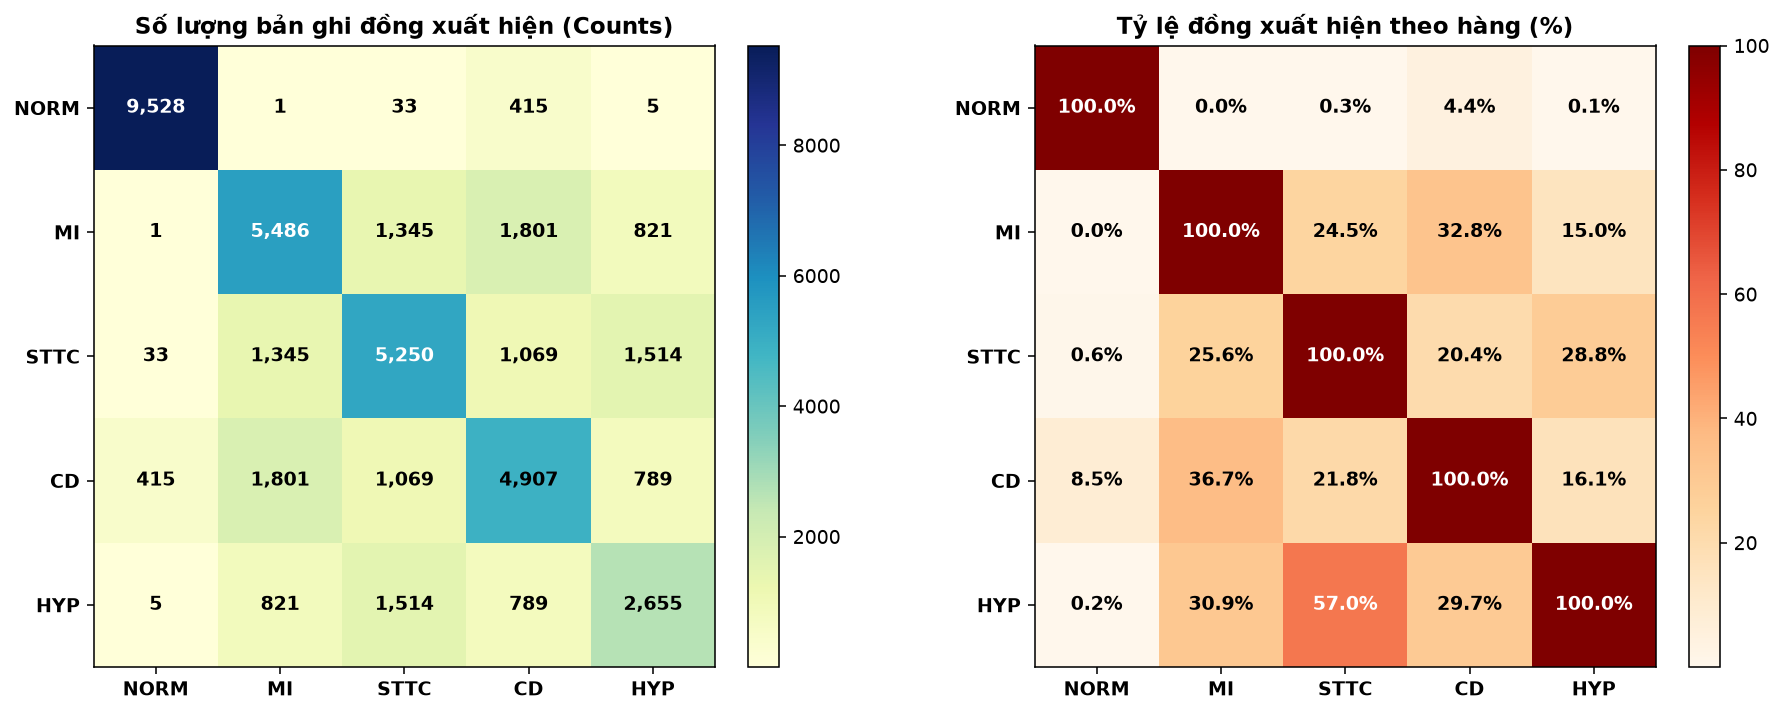

In [5]:
label_mat = signal_index[list(SUPERCLASSES)].to_numpy(dtype=np.int64)
coocc_counts = label_mat.T @ label_mat
diag_counts = np.diag(coocc_counts).astype(np.float64)
coocc_pct = (coocc_counts / diag_counts[:, np.newaxis]) * 100.0

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

for ax, matrix, title, fmt_fn, cmap in [
    (axes[0], coocc_counts, 'Số lượng bản ghi đồng xuất hiện (Counts)', lambda v: f'{int(v):,}', 'YlGnBu'),
    (axes[1], coocc_pct, 'Tỷ lệ đồng xuất hiện theo hàng (%)', lambda v: f'{v:.1f}%', 'OrRd'),
]:
    im = ax.imshow(matrix, cmap=cmap)
    ax.set_xticks(range(len(SUPERCLASSES)))
    ax.set_yticks(range(len(SUPERCLASSES)))
    ax.set_xticklabels(SUPERCLASSES, fontweight='bold')
    ax.set_yticklabels(SUPERCLASSES, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    thresh_val = matrix.max() * 0.55
    for i in range(len(SUPERCLASSES)):
        for j in range(len(SUPERCLASSES)):
            ax.text(
                j, i, fmt_fn(matrix[i, j]),
                ha='center', va='center', fontsize=10, fontweight='bold',
                color='white' if matrix[i, j] > thresh_val else 'black',
            )
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
coocc_path = figures_dir / 'superclass_cooccurrence_heatmap.png'
fig.savefig(coocc_path, bbox_inches='tight')
plt.show()
print('Saved figure:', coocc_path)

## 6. Giải thích mô hình với 1D Grad-CAM cho 10 ca `NORM` điển hình

- Tính **1D Grad-CAM** tại tầng trích xuất đặc trưng tích chập đa tỷ lệ (`model.inception`) cho từng bản ghi.
- Vẽ 10 bản ghi `NORM` trên tập Test với độ tự tin cao (tương tự mục **7.6 Grad-CAM for 10 NORMs** của nhóm kỳ trước).

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\gradcam_10_norm_cases.png


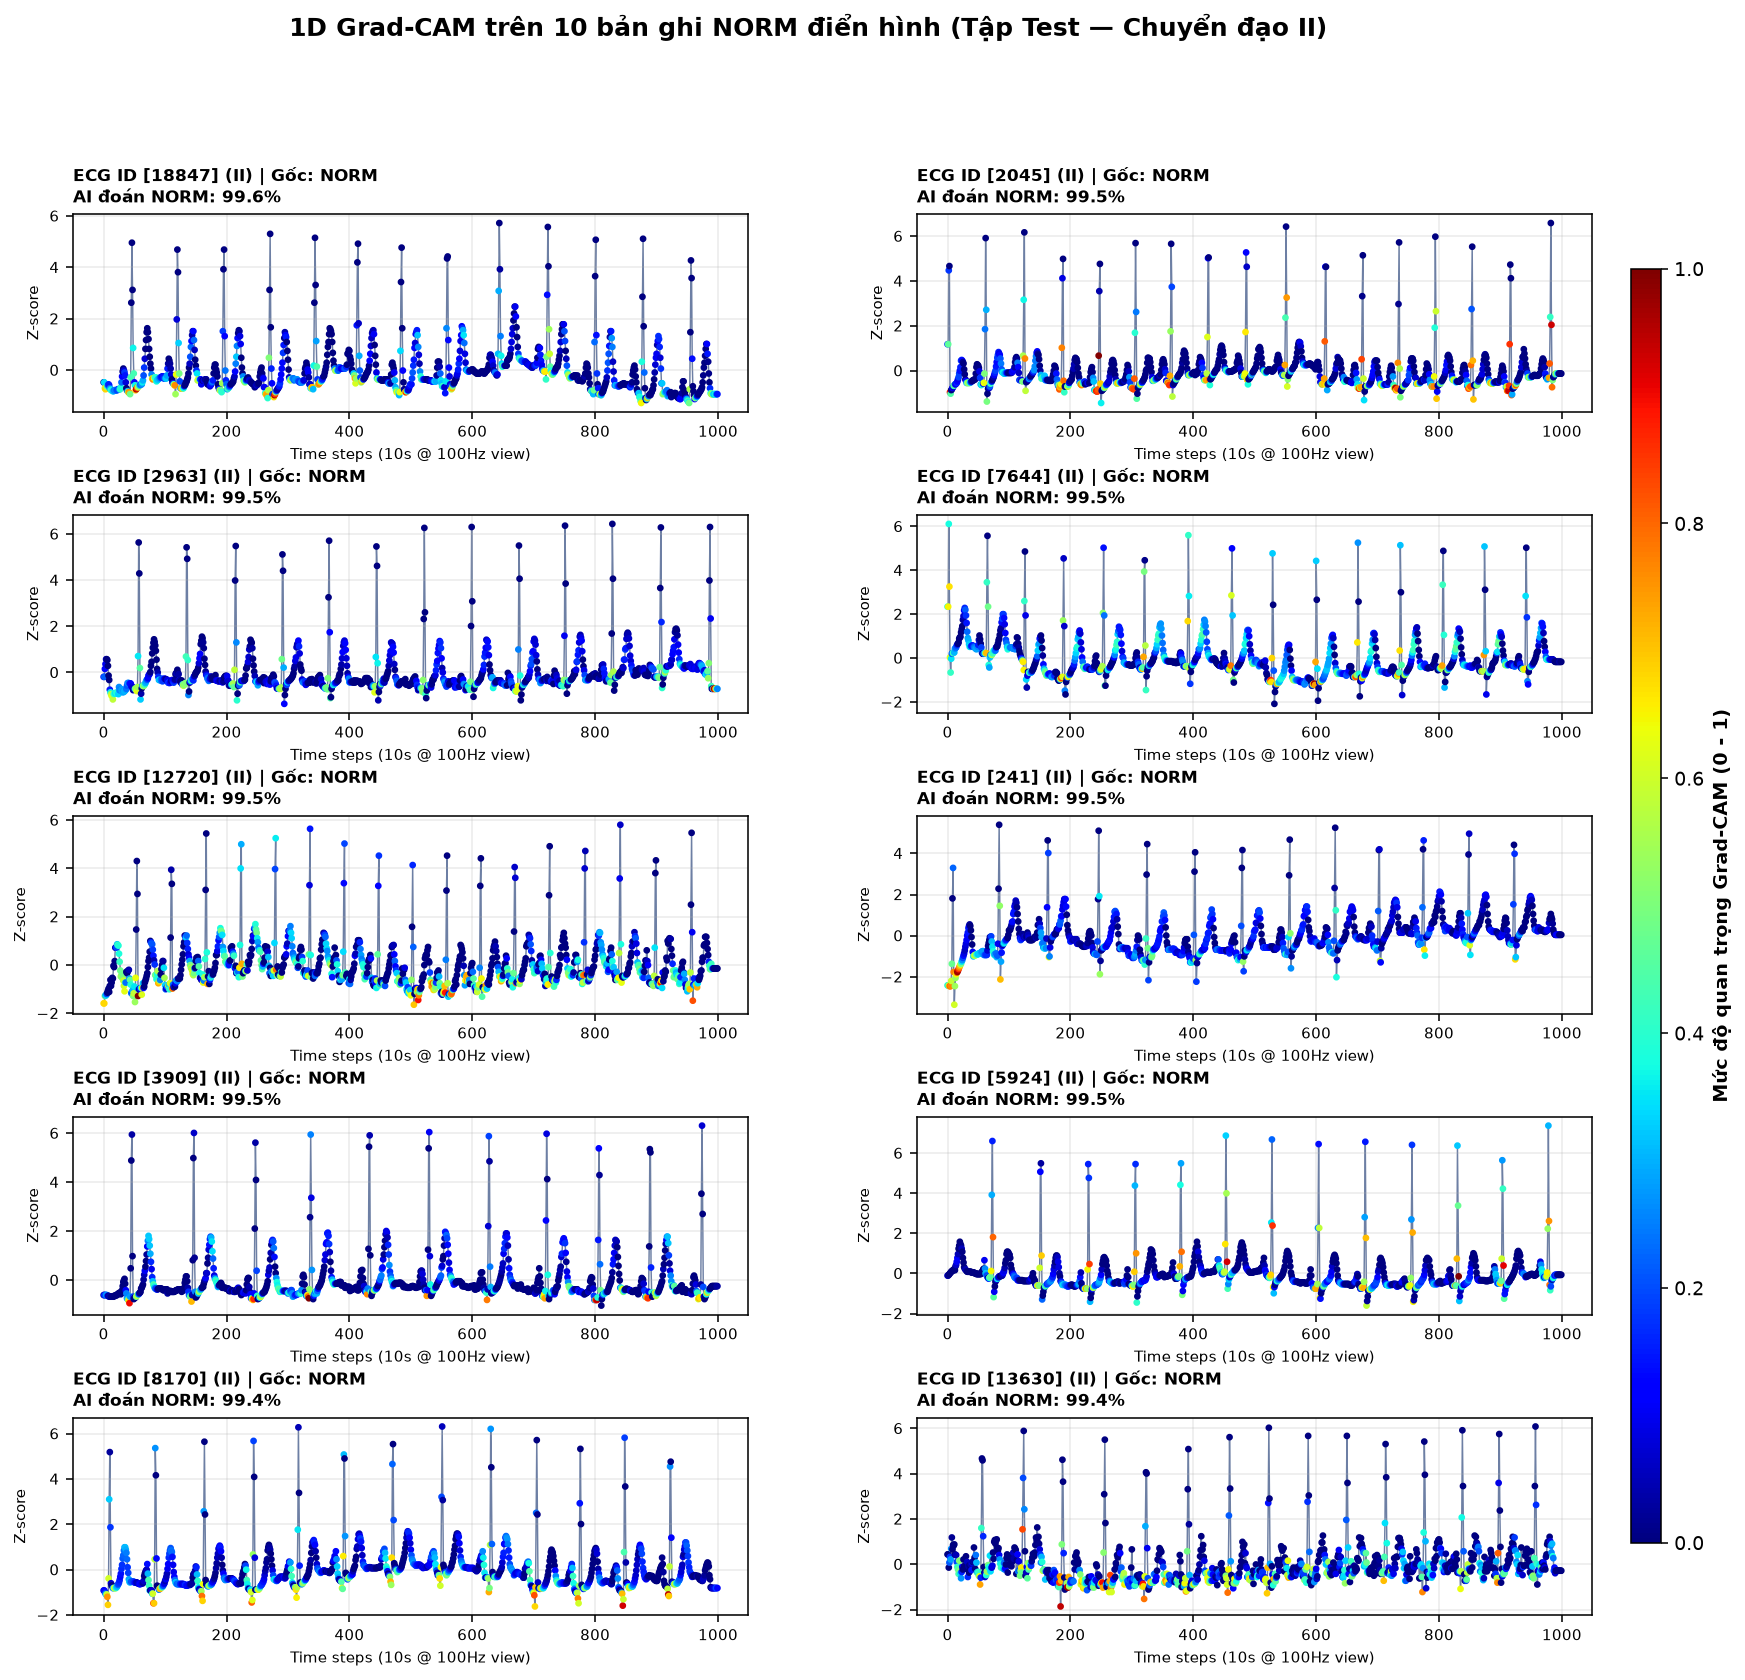

In [6]:
STANDARD_LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

def compute_1d_gradcam(model, ecg_tensor, clinical_tensor, target_class_idx):
    """Compute 1D Grad-CAM (length 5000) and predicted probabilities for one ECG record."""
    activations = []
    gradients = []

    def forward_hook(_module, _inp, out):
        activations.append(out)

    def backward_hook(_module, _grad_in, grad_out):
        gradients.append(grad_out[0])

    handle_f = model.inception.register_forward_hook(forward_hook)
    handle_b = model.inception.register_full_backward_hook(backward_hook)
    try:
        model.zero_grad(set_to_none=True)
        with torch.backends.cudnn.flags(enabled=False):
            logits = model(ecg_tensor, clinical_tensor)
            probs = torch.sigmoid(logits).detach().cpu().numpy()[0]
            score = logits[0, target_class_idx]
            score.backward()

        act = activations[0].detach()[0]   # (C, 5000)
        grad = gradients[0].detach()[0]    # (C, 5000)
        weights = grad.mean(dim=-1, keepdim=True)  # (C, 1)
        cam = torch.relu((weights * act).sum(dim=0)).cpu().numpy()
        cam_min, cam_max = float(cam.min()), float(cam.max())
        if cam_max > cam_min:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = np.zeros_like(cam)
        return cam, probs
    finally:
        handle_f.remove()
        handle_b.remove()


def plot_gradcam_grid(sample_indices, target_class_indices, lead_indices, nrows, ncols, figsize, suptitle, save_path):
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes_flat = np.asarray(axes).reshape(-1)
    scatter_ref = None

    for plot_idx, (ds_idx, cls_idx, lead_idx) in enumerate(zip(sample_indices, target_class_indices, lead_indices)):
        ax = axes_flat[plot_idx]
        item = test_dataset[int(ds_idx)]
        ecg_batch = item['ecg'].unsqueeze(0).to(device)
        clin_batch = item['clinical'].unsqueeze(0).to(device)
        ecg_id = int(item['ecg_id'].item())
        true_vec = item['target'].numpy().astype(int)
        true_labels = [SUPERCLASSES[i] for i, v in enumerate(true_vec) if v == 1]

        cam, probs = compute_1d_gradcam(model, ecg_batch, clin_batch, int(cls_idx))
        # Downsample mỗi 5 mẫu (1000 điểm trên 10 giây) để vẽ điểm nhiệt rõ nét giống slide mẫu
        step = 5
        t_steps = np.arange(0, 5000, step) // step
        sig_lead = item['ecg'].numpy()[lead_idx, ::step]
        cam_sub = cam[::step]

        ax.plot(t_steps, sig_lead, color='#1f3b73', lw=0.75, alpha=0.65, zorder=1)
        scatter_ref = ax.scatter(
            t_steps, sig_lead, c=cam_sub, cmap='jet', vmin=0.0, vmax=1.0, s=6, zorder=2
        )
        cls_name = SUPERCLASSES[cls_idx]
        lead_name = STANDARD_LEADS[lead_idx]
        ax.set_title(
            f'ECG ID [{ecg_id}] ({lead_name}) | Gốc: {", ".join(true_labels)}\n'
            f'AI đoán {cls_name}: {probs[cls_idx] * 100:.1f}%',
            fontsize=8.5, fontweight='bold', loc='left',
        )
        ax.set_xlabel('Time steps (10s @ 100Hz view)', fontsize=7.5)
        ax.set_ylabel('Z-score', fontsize=7.5)
        ax.tick_params(labelsize=7.5)
        ax.grid(True, alpha=0.25)

    fig.subplots_adjust(right=0.90, hspace=0.52, wspace=0.25)
    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.70])
    cbar = fig.colorbar(scatter_ref, cax=cbar_ax)
    cbar.set_label('Mức độ quan trọng Grad-CAM (0 - 1)', fontsize=10, fontweight='bold')
    fig.suptitle(suptitle, fontsize=13, fontweight='bold', y=0.99)
    fig.savefig(save_path, bbox_inches='tight')
    plt.show()
    print('Saved figure:', save_path)


# Chọn 10 ca thuần NORM có xác suất dự đoán cao nhất trên tập Test
pure_norm_mask = (y_true_test[:, 0] == 1) & (y_true_test[:, 1:].sum(axis=1) == 0)
norm_candidates = np.where(pure_norm_mask)[0]
top10_norm_indices = norm_candidates[np.argsort(-y_prob_test[norm_candidates, 0])[:10]]

plot_gradcam_grid(
    sample_indices=top10_norm_indices,
    target_class_indices=[0] * 10,
    lead_indices=[1] * 10,  # Chuyển đạo II chuẩn lâm sàng
    nrows=5,
    ncols=2,
    figsize=(14, 13),
    suptitle='1D Grad-CAM trên 10 bản ghi NORM điển hình (Tập Test — Chuyển đạo II)',
    save_path=figures_dir / 'gradcam_10_norm_cases.png',
)

## 7. Giải thích 1D Grad-CAM cho các ca Bệnh lý (`MI`, `STTC`, `CD`, `HYP` & Đa nhãn)

Trực quan hóa 12 ca bệnh lý điển hình (3 ca cho mỗi nhóm `MI`, `STTC`, `CD`, `HYP`, bao gồm cả các ca đa nhãn) trên chuyển đạo đặc trưng để đối chiếu với hình thái sóng P-QRS-T lâm sàng.

Saved figure: C:\Users\dx\ML in healthcare\Project\roi_loan_nhip_tim_ecg\figures\gradcam_disease_cases.png


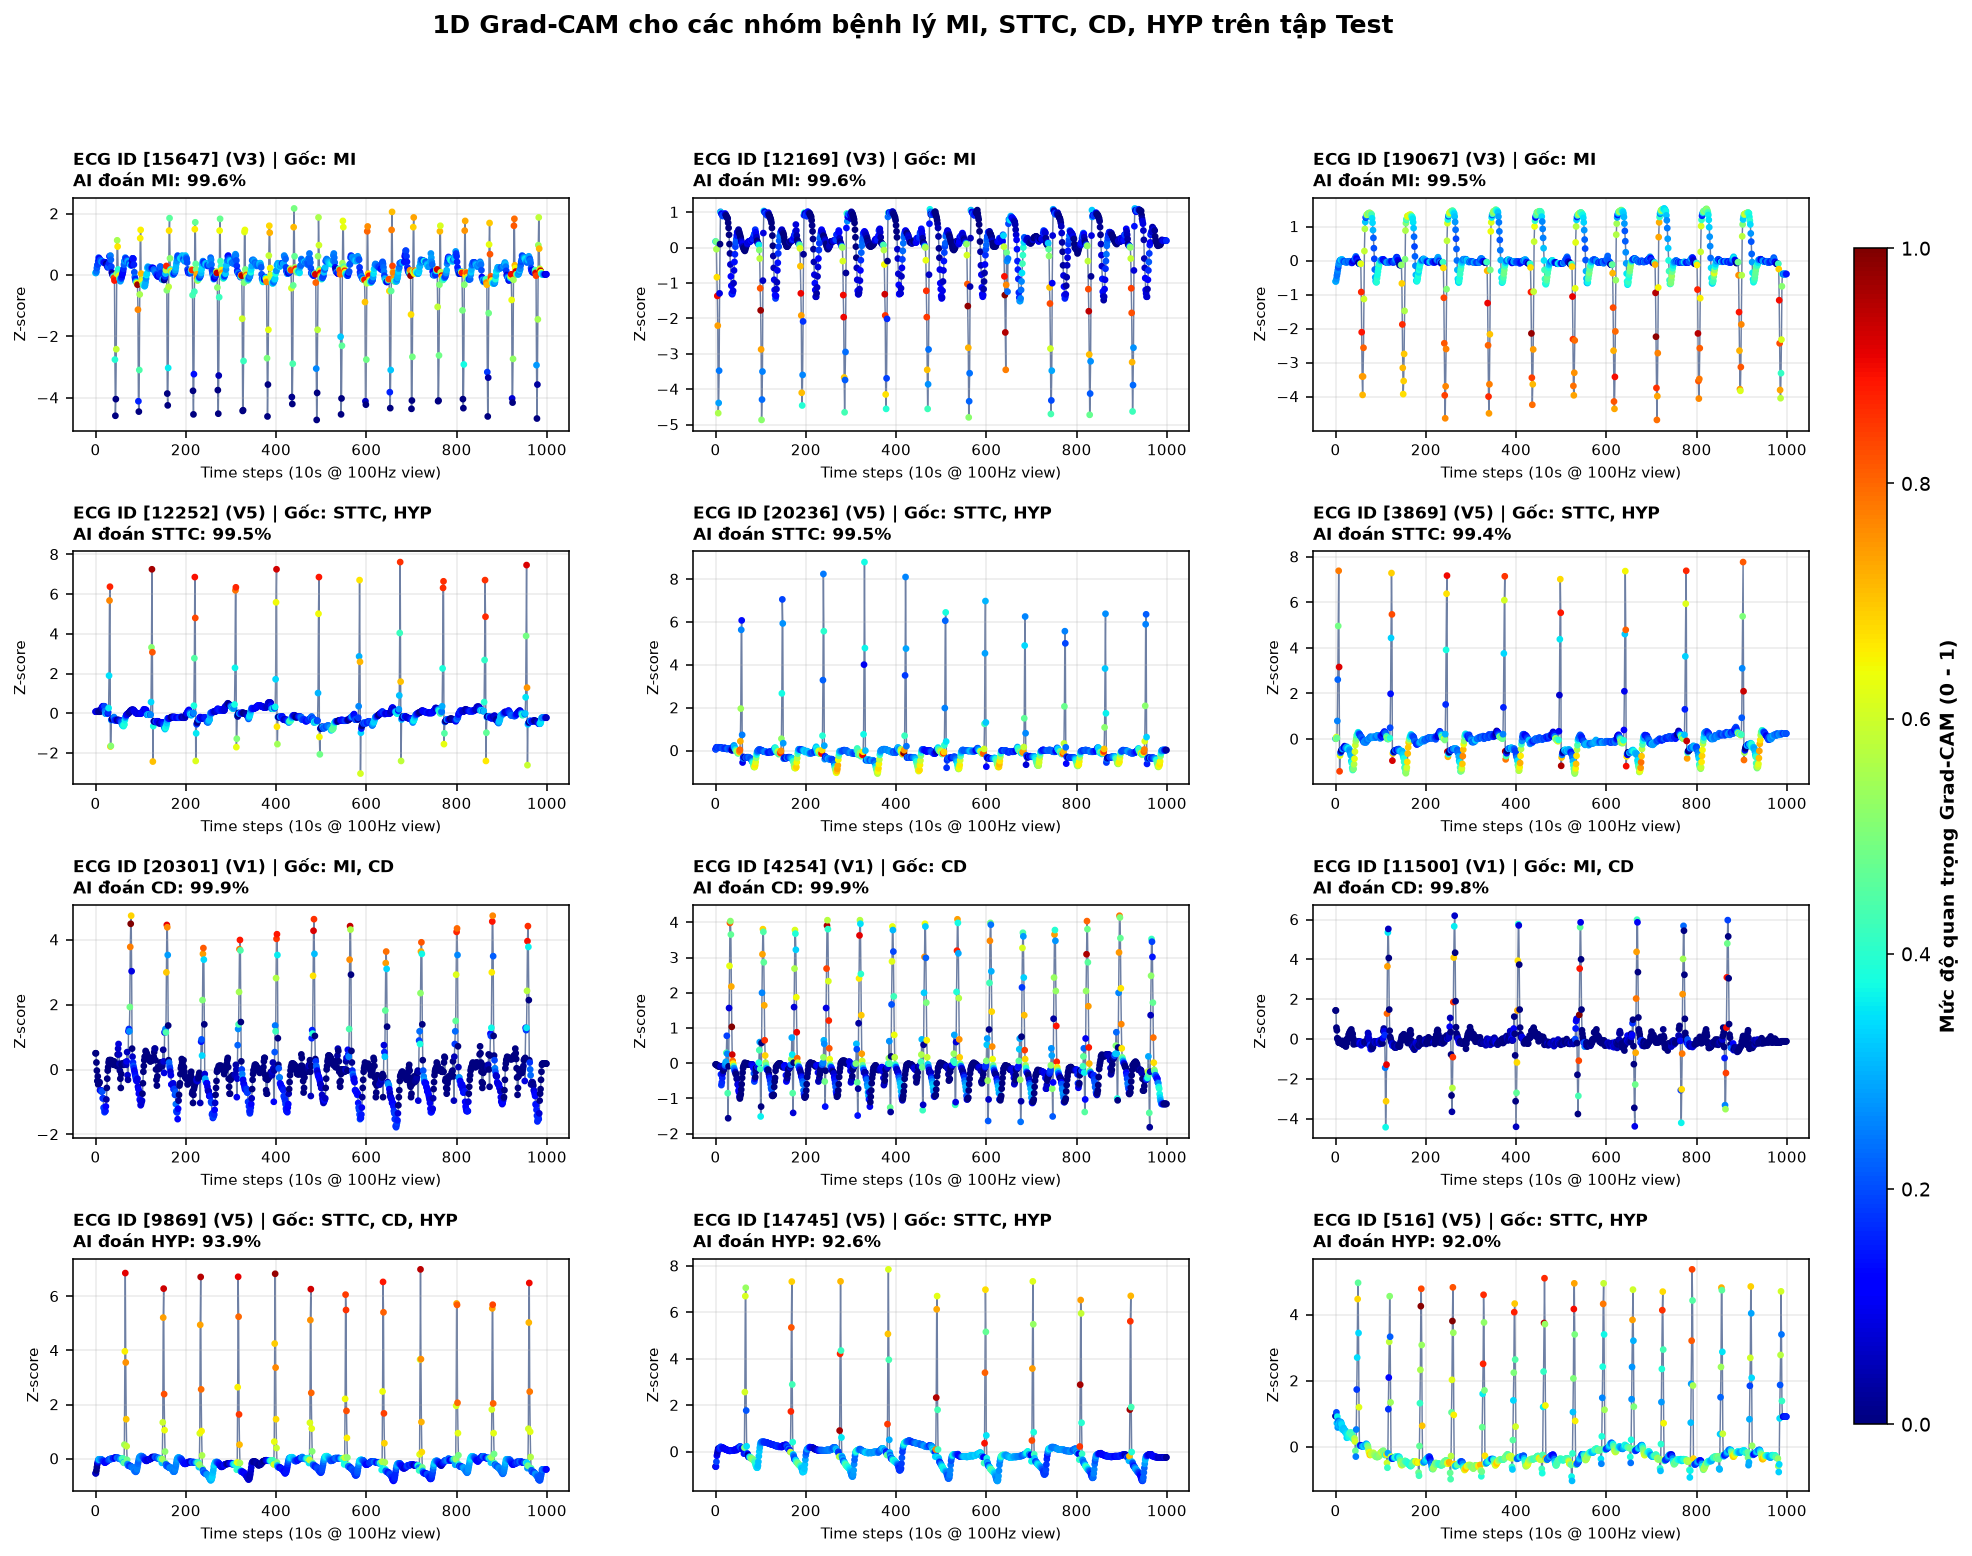

In [7]:
disease_indices = []
disease_cls = []
disease_leads = []

# Chọn chuyển đạo đại diện rõ hình thái nhất cho từng bệnh: MI -> V3, STTC -> V5, CD -> V1, HYP -> V5
preferred_lead_by_cls = {1: 8, 2: 10, 3: 6, 4: 10}
for cls_idx in (1, 2, 3, 4):
    pos_mask = y_true_test[:, cls_idx] == 1
    pos_candidates = np.where(pos_mask)[0]
    top3 = pos_candidates[np.argsort(-y_prob_test[pos_candidates, cls_idx])[:3]]
    for idx_val in top3:
        disease_indices.append(int(idx_val))
        disease_cls.append(cls_idx)
        disease_leads.append(preferred_lead_by_cls[cls_idx])

plot_gradcam_grid(
    sample_indices=disease_indices,
    target_class_indices=disease_cls,
    lead_indices=disease_leads,
    nrows=4,
    ncols=3,
    figsize=(16, 12),
    suptitle='1D Grad-CAM cho các nhóm bệnh lý MI, STTC, CD, HYP trên tập Test',
    save_path=figures_dir / 'gradcam_disease_cases.png',
)

## 8. Ma trận Đóng góp của 12 Chuyển đạo ($12 \times 5$ Heatmap) & Đóng góp Đa phương thức (`ECG` vs. `Clinical`)

1. **Ma trận Saliency $12 \times 5$ (12 Leads $\times$ 5 Superclasses):** Tính trung bình độ lớn đạo hàm theo đầu vào $\left|\frac{\partial \text{logit}_c}{\partial X_{l, t}}\right|$ trên các ca dương tính của tập Test để xác định chuyển đạo nào đóng vai trò quyết định cho từng nhóm bệnh.
2. **Phân tích đóng góp Đa phương thức (Late Fusion Contribution):** So sánh tỷ trọng đóng góp vào logit dự đoán giữa nhánh `ECG Embedding (192 chiều)` và nhánh `Clinical Embedding [age_z, sex] (16 chiều)`.

=== MA TRẬN TỶ TRỌNG ĐÓNG GÓP CỦA 12 CHUYỂN ĐẠO THEO TỪNG NHÓM BỆNH (%) ===
      NORM     MI   STTC     CD    HYP
I    8.32%  8.83%  9.38%  8.93%  8.80%
II   7.55%  8.47%  8.00%  8.37%  8.20%
III  6.21%  6.57%  6.33%  6.66%  6.09%
aVR  8.68%  8.24%  8.91%  8.55%  9.31%
aVL  7.42%  7.66%  7.72%  7.79%  7.37%
aVF  8.53%  8.87%  8.08%  8.35%  8.48%
V1  11.76% 10.69% 10.92% 10.71% 11.25%
V2   8.99%  9.48%  9.09%  9.24%  9.03%
V3   7.08%  7.30%  7.01%  7.13%  6.93%
V4   8.01%  7.68%  7.66%  7.65%  7.37%
V5   7.80%  7.40%  7.45%  7.71%  7.63%
V6   9.64%  8.81%  9.46%  8.91%  9.55%

=== BẢNG TỶ TRỌNG ĐÓNG GÓP ĐA PHƯƠNG THỨC (LATE FUSION: ECG vs. CLINICAL) ===
      ECG Waveform Share (%)  Clinical [age_z, sex] Share (%)
NORM                  94.73%                            5.27%
MI                    95.00%                            5.00%
STTC                  96.45%                            3.55%
CD                    97.84%                            2.16%
HYP                   97.08%

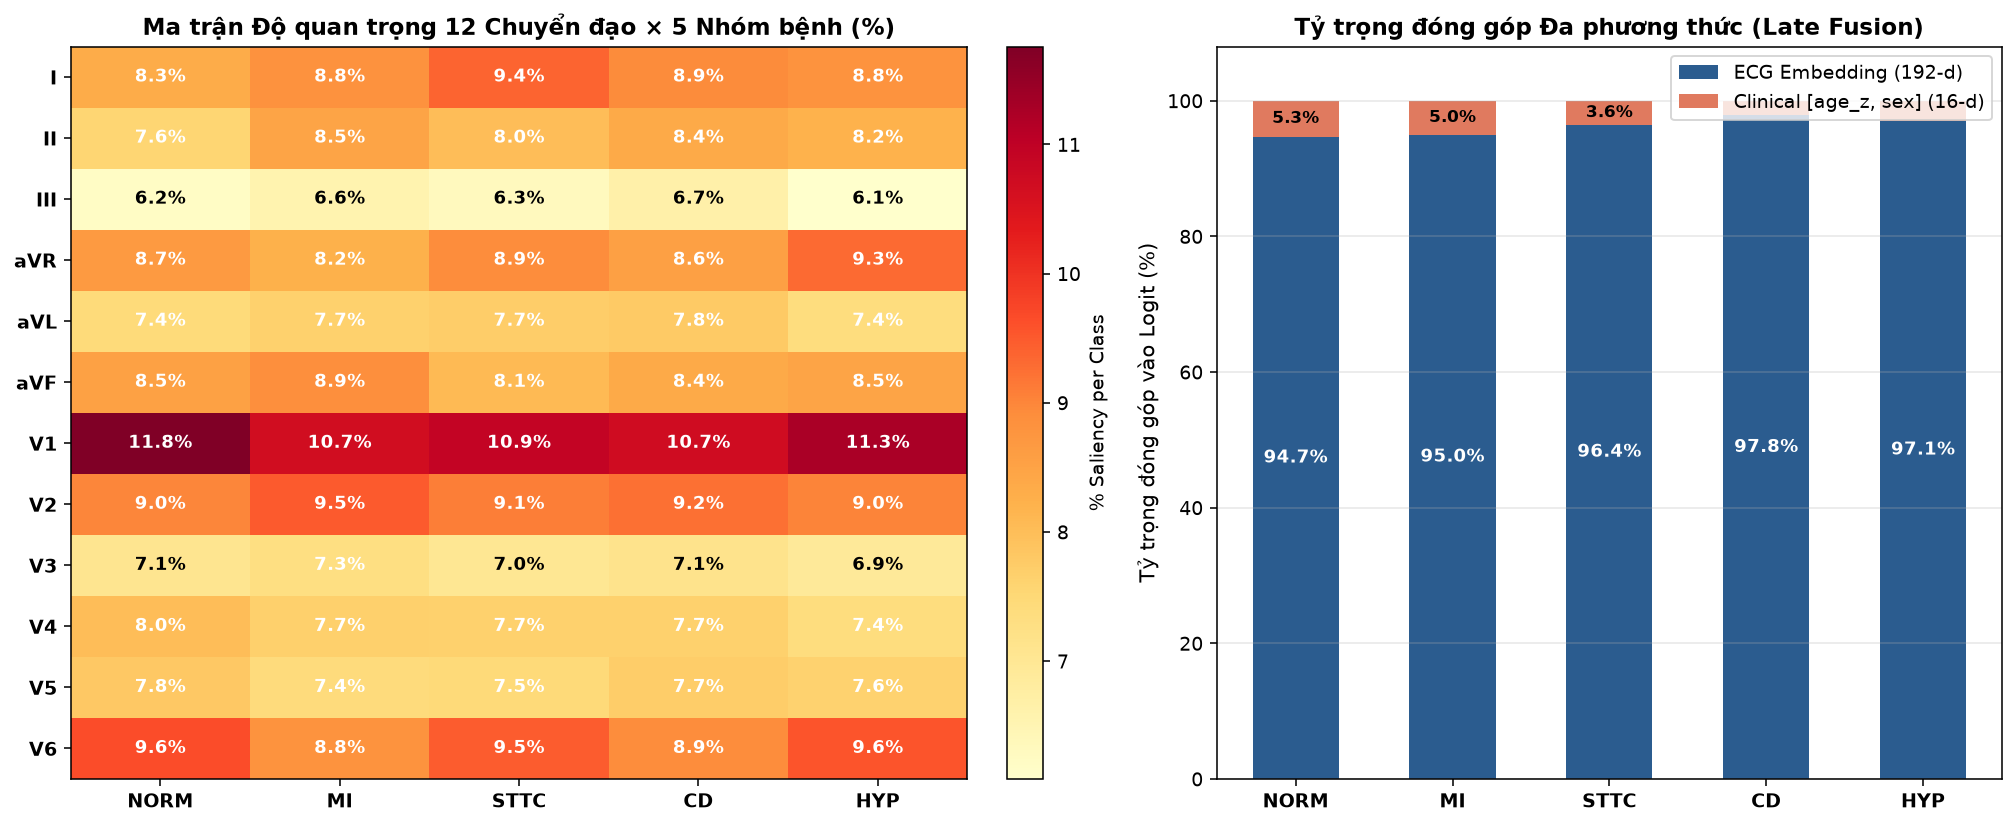

In [8]:
# 1. Tính Ma trận độ quan trọng 12 chuyển đạo x 5 nhóm bệnh bằng Input Gradient Saliency
lead_saliency_matrix = np.zeros((12, len(SUPERCLASSES)), dtype=np.float64)

for cls_idx, label in enumerate(SUPERCLASSES):
    pos_indices = np.where(y_true_test[:, cls_idx] == 1)[0]
    # Lấy tối đa 80 ca dương tính có xác suất cao nhất của mỗi lớp để tính trung bình đại diện
    selected = pos_indices[np.argsort(-y_prob_test[pos_indices, cls_idx])[:80]]
    ecg_batch = torch.stack([test_dataset[int(i)]['ecg'] for i in selected]).to(device)
    clin_batch = torch.stack([test_dataset[int(i)]['clinical'] for i in selected]).to(device)
    ecg_batch.requires_grad_(True)

    model.zero_grad(set_to_none=True)
    with torch.backends.cudnn.flags(enabled=False):
        logits = model(ecg_batch, clin_batch)
        logits[:, cls_idx].sum().backward()

    grad_abs = ecg_batch.grad.detach().abs().mean(dim=(0, 2)).cpu().numpy()  # (12,)
    lead_saliency_matrix[:, cls_idx] = grad_abs / grad_abs.sum() * 100.0

lead_saliency_df = pd.DataFrame(lead_saliency_matrix, index=STANDARD_LEADS, columns=SUPERCLASSES)
print('=== MA TRẬN TỶ TRỌNG ĐÓNG GÓP CỦA 12 CHUYỂN ĐẠO THEO TỪNG NHÓM BỆNH (%) ===')
print(lead_saliency_df.to_string(float_format=lambda v: f'{v:.2f}%'))

# 2. Tính tỷ trọng đóng góp giữa ECG Embedding (192 chiều) và Clinical Embedding (16 chiều)
w_ecg = model.classifier.weight[:, :192].detach()   # (5, 192)
w_clin = model.classifier.weight[:, 192:].detach()  # (5, 16)

ecg_contrib_list = []
clin_contrib_list = []
with torch.inference_mode():
    for batch in test_loader:
        ecg_b = batch['ecg'].to(device)
        clin_b = batch['clinical'].to(device)
        feat = model.downsample(model.inception(model.stem(ecg_b)))
        seq = model.sequence_model(feat.transpose(1, 2))
        z_ecg = model.attention_pool(seq)          # (B, 192)
        z_clin = model.clinical_encoder(clin_b)    # (B, 16)

        c_ecg = torch.matmul(z_ecg, w_ecg.T).abs().cpu().numpy()    # (B, 5)
        c_clin = torch.matmul(z_clin, w_clin.T).abs().cpu().numpy() # (B, 5)
        ecg_contrib_list.append(c_ecg)
        clin_contrib_list.append(c_clin)

ecg_contrib_all = np.concatenate(ecg_contrib_list, axis=0).mean(axis=0)
clin_contrib_all = np.concatenate(clin_contrib_list, axis=0).mean(axis=0)
total_contrib = ecg_contrib_all + clin_contrib_all
ecg_share = (ecg_contrib_all / total_contrib) * 100.0
clin_share = (clin_contrib_all / total_contrib) * 100.0

multimodal_df = pd.DataFrame({
    'ECG Waveform Share (%)': ecg_share,
    'Clinical [age_z, sex] Share (%)': clin_share,
}, index=SUPERCLASSES)
print('\n=== BẢNG TỶ TRỌNG ĐÓNG GÓP ĐA PHƯƠNG THỨC (LATE FUSION: ECG vs. CLINICAL) ===')
print(multimodal_df.to_string(float_format=lambda v: f'{v:.2f}%'))

# Vẽ chung 2 biểu đồ XAI cấp toàn cục (12x5 Lead Heatmap + Multimodal Bar Chart)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.0), gridspec_kw={'width_ratios': [1.25, 1.0]})

ax0 = axes[0]
im = ax0.imshow(lead_saliency_matrix, cmap='YlOrRd', aspect='auto')
ax0.set_xticks(range(len(SUPERCLASSES)))
ax0.set_yticks(range(len(STANDARD_LEADS)))
ax0.set_xticklabels(SUPERCLASSES, fontweight='bold')
ax0.set_yticklabels(STANDARD_LEADS, fontweight='bold')
ax0.set_title('Ma trận Độ quan trọng 12 Chuyển đạo × 5 Nhóm bệnh (%)', fontsize=12, fontweight='bold')
for i in range(12):
    for j in range(len(SUPERCLASSES)):
        val = lead_saliency_matrix[i, j]
        ax0.text(
            j, i, f'{val:.1f}%', ha='center', va='center', fontsize=9, fontweight='bold',
            color='white' if val > lead_saliency_matrix.max() * 0.62 else 'black',
        )
fig.colorbar(im, ax=ax0, fraction=0.046, pad=0.04, label='% Saliency per Class')

ax1 = axes[1]
x_pos = np.arange(len(SUPERCLASSES))
bars1 = ax1.bar(x_pos, ecg_share, width=0.55, label='ECG Embedding (192-d)', color='#2b5c8f')
bars2 = ax1.bar(x_pos, clin_share, width=0.55, bottom=ecg_share, label='Clinical [age_z, sex] (16-d)', color='#e07a5f')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(SUPERCLASSES, fontweight='bold')
ax1.set_ylim(0, 108)
ax1.set_ylabel('Tỷ trọng đóng góp vào Logit (%)', fontsize=11)
ax1.set_title('Tỷ trọng đóng góp Đa phương thức (Late Fusion)', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(axis='y', alpha=0.3)
for idx, (e_val, c_val) in enumerate(zip(ecg_share, clin_share)):
    ax1.text(idx, e_val / 2, f'{e_val:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)
    if c_val >= 3.0:
        ax1.text(idx, e_val + c_val / 2, f'{c_val:.1f}%', ha='center', va='center', color='black', fontweight='bold', fontsize=8.5)

plt.tight_layout()
xai_matrix_path = figures_dir / 'xai_lead_importance_and_multimodal.png'
fig.savefig(xai_matrix_path, bbox_inches='tight')
plt.show()
print('Saved figure:', xai_matrix_path)